In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

# Load the dataset
df = pd.read_csv('
# Reload the original dataset
raw_df = pd.read_csv('/content/load_data.csv')

print("Original dataset shape:", raw_df.shape)
print("\nSample date values:")
print(raw_df['Date_Time'].head(10).to_list())

# Parse dates using day-first format
parsed_dates = pd.to_datetime(
    raw_df['Date_Time'],
    dayfirst=True,
    errors='coerce'
)

print("\nDates that could not be parsed:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

print("\nRecords per month:")
print(
    parsed_dates.dropna()
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)
')

# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Libraries imported successfully!
Dataset shape: (35041, 9)

Column names:
['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']

First five rows:


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


In [2]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLoad type distribution:")
print(df['Load_Type'].value_counts())


Missing values in each column:
Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64

Duplicate rows: 0

Load type distribution:
Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


In [3]:

# Convert Date_Time to datetime
df['Date_Time'] = pd.to_datetime(df['Date_Time'], errors='coerce')

# Sort records chronologically
df = df.sort_values('Date_Time').reset_index(drop=True)

# Check the date range
print("Earliest date:", df['Date_Time'].min())
print("Latest date:", df['Date_Time'].max())

# Check missing values again
print("\nMissing values:")
print(df.isnull().sum())

# Check target distribution as percentages
print("\nLoad type percentages:")
print((df['Load_Type'].value_counts(normalize=True) * 100).round(2))


Earliest date: 2018-01-01 00:00:00
Latest date: 2018-12-12 23:45:00

Missing values:
Date_Time                               21217
Usage_kWh                                1559
Lagging_Current_Reactive.Power_kVarh      876
Leading_Current_Reactive_Power_kVarh     1156
CO2(tCO2)                                 455
Lagging_Current_Power_Factor              350
Leading_Current_Power_Factor             1471
NSM                                       455
Load_Type                                   0
dtype: int64

Load type percentages:
Load_Type
Light_Load      51.58
Medium_Load     27.67
Maximum_Load    20.75
Name: proportion, dtype: float64


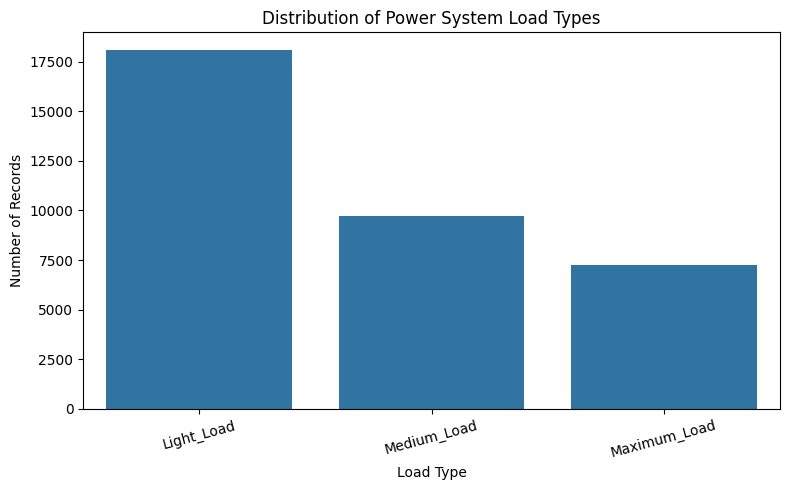

In [4]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Load_Type')

plt.title('Distribution of Power System Load Types')
plt.xlabel('Load Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [5]:

# Check the date range and frequency
print("Earliest date:", df['Date_Time'].min())
print("Latest date:", df['Date_Time'].max())

print("\nRecords per month:")
print(df.groupby(df['Date_Time'].dt.to_period('M')).size())


Earliest date: 2018-01-01 00:00:00
Latest date: 2018-12-12 23:45:00

Records per month:
Date_Time
2018-01    1152
2018-02    1152
2018-03    1152
2018-04    1152
2018-05    1152
2018-06    1152
2018-07    1152
2018-08    1152
2018-09    1152
2018-10    1152
2018-11    1152
2018-12    1152
Freq: M, dtype: int64


In [6]:

# Identify the last month in the dataset
last_month = df['Date_Time'].max().to_period('M')

# Split chronologically
train_df = df[
    df['Date_Time'].dt.to_period('M') < last_month
].copy()

test_df = df[
    df['Date_Time'].dt.to_period('M') == last_month
].copy()

print("Last month used for testing:", last_month)
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nTraining date range:")
print(train_df['Date_Time'].min(), "to", train_df['Date_Time'].max())

print("\nTesting date range:")
print(test_df['Date_Time'].min(), "to", test_df['Date_Time'].max())


Last month used for testing: 2018-12
Training data shape: (12672, 9)
Testing data shape: (1152, 9)

Training date range:
2018-01-01 00:00:00 to 2018-11-12 23:45:00

Testing date range:
2018-12-01 00:00:00 to 2018-12-12 23:45:00


In [7]:

# Separate target and input features
target = 'Load_Type'

X_train = train_df.drop(columns=[target, 'Date_Time'])
y_train = train_df[target]

X_test = test_df.drop(columns=[target, 'Date_Time'])
y_test = test_df[target]

# Fill missing numerical values using training medians only
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Missing values in training features: 0
Missing values in testing features: 0
Training labels: (12672,)
Testing labels: (1152,)


In [8]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Predict the test data
y_pred = model.predict(X_test)

print("Model training completed successfully!")


Model training completed successfully!


Test Accuracy: 0.8194
Test Accuracy Percentage: 81.94%

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.95      0.96      0.96       536
Maximum_Load       0.67      0.67      0.67       264
 Medium_Load       0.73      0.71      0.72       352

    accuracy                           0.82      1152
   macro avg       0.78      0.78      0.78      1152
weighted avg       0.82      0.82      0.82      1152



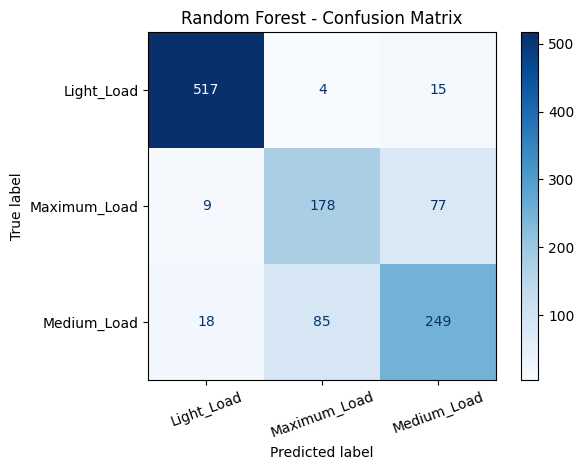

In [9]:

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy Percentage: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap='Blues', xticks_rotation=20)
plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()


In [10]:

from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Random Forest": model,
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, clf in models.items():
    if name != "Random Forest":
        clf.fit(X_train, y_train)

    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
2,Gradient Boosting,0.8472,0.8168,0.8168,0.8166
1,Extra Trees,0.8273,0.7928,0.7902,0.7913
0,Random Forest,0.8194,0.7824,0.7821,0.7822


FINAL MODEL: GRADIENT BOOSTING
Test Accuracy: 0.8472

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.95      0.97      0.96       536
Maximum_Load       0.72      0.74      0.73       264
 Medium_Load       0.78      0.74      0.76       352

    accuracy                           0.85      1152
   macro avg       0.82      0.82      0.82      1152
weighted avg       0.85      0.85      0.85      1152



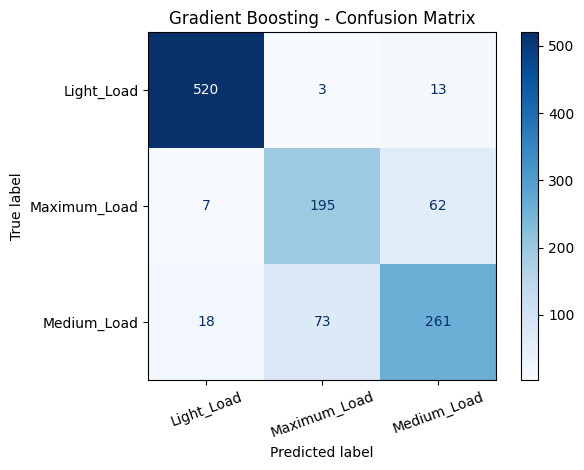

In [11]:

# Select and train the final model
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

final_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X_train, y_train)

# Predictions on the untouched test set
final_predictions = final_model.predict(X_test)

# Evaluation
print("FINAL MODEL: GRADIENT BOOSTING")
print("=" * 40)
print(f"Test Accuracy: {accuracy_score(y_test, final_predictions):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, final_predictions, zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, final_predictions,
    labels=final_model.classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
).plot(cmap="Blues", xticks_rotation=20)

plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()


In [13]:

# Reload the original dataset
raw_df = pd.read_csv('/content/sample_data/load_data.csv')

print("Original dataset shape:", raw_df.shape)
print("\nSample date values:")
print(raw_df['Date_Time'].head(10).to_list())

# Parse dates using day-first format
parsed_dates = pd.to_datetime(
    raw_df['Date_Time'],
    dayfirst=True,
    errors='coerce'
)

print("\nDates that could not be parsed:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

print("\nRecords per month:")
print(
    parsed_dates.dropna()
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)


Original dataset shape: (35041, 9)

Sample date values:
['01-01-2018 00:15', '01-01-2018 00:30', '01-01-2018 00:45', '01-01-2018 01:00', '01-01-2018 01:15', '01-01-2018 01:30', '01-01-2018 01:45', '01-01-2018 02:00', '01-01-2018 02:15', '01-01-2018 02:30']

Dates that could not be parsed: 0
Earliest date: 2018-01-01 00:00:00
Latest date: 2018-12-31 23:45:00

Records per month:
Date_Time
2018-01    2976
2018-02    2688
2018-03    2976
2018-04    2880
2018-05    2976
2018-06    2880
2018-07    2976
2018-08    2976
2018-09    2880
2018-10    2976
2018-11    2880
2018-12    2977
Freq: M, Name: count, dtype: int64


In [15]:

# Reload the original dataset
df = pd.read_csv('/content/sample_data/load_data.csv')

# Correctly parse dates in day-month-year format
df['Date_Time'] = pd.to_datetime(
    df['Date_Time'],
    format='%d-%m-%Y %H:%M',
    errors='raise'
)

# Sort chronologically
df = df.sort_values('Date_Time').reset_index(drop=True)

# Create useful time-based features
df['Hour'] = df['Date_Time'].dt.hour
df['DayOfWeek'] = df['Date_Time'].dt.dayofweek
df['DayOfYear'] = df['Date_Time'].dt.dayofyear
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

# Reserve the last calendar month for testing
last_month = df['Date_Time'].max().to_period('M')

train_df = df[
    df['Date_Time'].dt.to_period('M') < last_month
].copy()

test_df = df[
    df['Date_Time'].dt.to_period('M') == last_month
].copy()

print("Full dataset:", df.shape)
print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Test month:", last_month)
print("Latest timestamp:", df['Date_Time'].max())

print("\nMissing values in target:")
print(df['Load_Type'].isnull().sum())


Full dataset: (35041, 14)
Training records: 32064
Testing records: 2977
Test month: 2018-12
Latest timestamp: 2018-12-31 23:45:00

Missing values in target:
0


In [16]:

target = 'Load_Type'

# Exclude the raw timestamp and target from the input features
X_train = train_df.drop(columns=[target, 'Date_Time'])
y_train = train_df[target].copy()

X_test = test_df.drop(columns=[target, 'Date_Time'])
y_test = test_df[target].copy()

# Impute missing values using training data only
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Missing training values:", X_train.isnull().sum().sum())
print("Missing testing values:", X_test.isnull().sum().sum())


Training features: (32064, 12)
Testing features: (2977, 12)
Missing training values: 0
Missing testing values: 0


In [17]:

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )
}

results = []

for name, clf in models.items():
    print(f"Training {name}...")
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100,
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
)

display(results_df.round(4))


Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training Hist Gradient Boosting...


,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1
0,Random Forest,93.9872,0.9309,0.9289,0.9293
3,Hist Gradient Boosting,92.8116,0.9168,0.9245,0.9206
2,Gradient Boosting,92.4421,0.9031,0.9183,0.9103
1,Extra Trees,91.9382,0.9011,0.9001,0.8994


In [18]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Time-aware cross-validation on training data only
cv = TimeSeriesSplit(n_splits=3)

rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

param_grid = {
    "n_estimators": [150, 250],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2]
}

search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))

# Evaluate the selected model once on December
tuned_model = search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)

print("Tuned test accuracy:",
      round(accuracy_score(y_test, tuned_predictions) * 100, 2), "%")
print("Tuned test macro F1:",
      round(f1_score(y_test, tuned_predictions,
                     average="macro"), 4))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 150}
Best CV macro F1: 0.8991
Tuned test accuracy: 93.85 %
Tuned test macro F1: 0.9301


FINAL MODEL: RANDOM FOREST
Accuracy: 93.99 %

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.96      0.95      0.95      1745
Maximum_Load       0.93      0.87      0.90       528
 Medium_Load       0.91      0.97      0.94       704

    accuracy                           0.94      2977
   macro avg       0.93      0.93      0.93      2977
weighted avg       0.94      0.94      0.94      2977



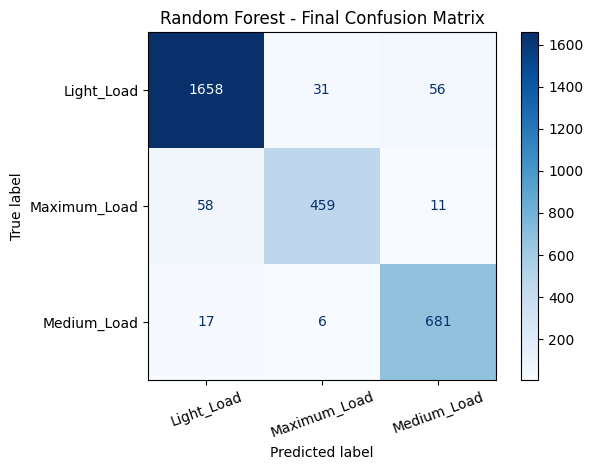

In [19]:

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the original Random Forest model from our comparison
best_model = models["Random Forest"]
best_predictions = best_model.predict(X_test)

print("FINAL MODEL: RANDOM FOREST")
print("Accuracy:",
      round(accuracy_score(y_test, best_predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, best_predictions, zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, best_predictions,
                                      labels=best_model.classes_),
    display_labels=best_model.classes_
).plot(cmap="Blues", xticks_rotation=20)

plt.title("Random Forest - Final Confusion Matrix")
plt.tight_layout()
plt.show()
